In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
d1 = pd.read_csv('score.csv')
d2 = pd.read_csv('score_updated.csv')

data = pd.concat([d1, d2], ignore_index=True)

data.to_csv('final_score.csv', index=False)

In [12]:
print(pd.isna(data).sum())

Hours     0
Scores    0
dtype: int64


In [13]:
print(data.head())
print(data.tail())
print(data.shape)
print(data.columns)
print(data.info())
print(data.describe())

   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30
     Hours  Scores
116    5.8      60
117    4.4      44
118    6.1      63
119    3.7      37
120    8.0      84
(121, 2)
Index(['Hours', 'Scores'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   121 non-null    float64
 1   Scores  121 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 2.0 KB
None
            Hours      Scores
count  121.000000  121.000000
mean     5.214876   53.495868
std      2.499189   24.988705
min      1.000000   12.000000
25%      3.000000   30.000000
50%      5.100000   54.000000
75%      7.400000   75.000000
max      9.800000   99.000000


Text(0, 0.5, 'Scores')

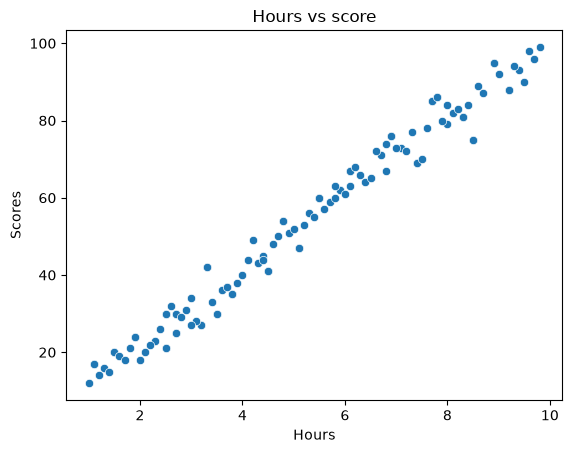

In [16]:
sns.scatterplot(data = data, x = "Hours", y = "Scores")
plt.title('Hours vs score')
plt.xlabel('Hours')
plt.ylabel('Scores')

In [17]:
x = data[['Hours']]
y = data['Scores']

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42) 

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9.84]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.192
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [20]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_)

Intercept: 2.192029517685583
Coefficient: [9.83565623]


In [21]:
y_pred = model.predict(x_test)

print(y_pred)

[74.97588564 39.5675232  36.61682633 17.92907949 52.3538763  45.46891694
 14.97838262 77.92658251 89.72936999 61.20596691 62.18953254 64.15666378
 60.22240129 60.22240129 82.84441063 62.18953254 51.37031068 26.7811701
 55.30457317 86.77867312 19.89621074 28.74830135 92.68006686 42.51822007
 20.87977636]


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse**0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2.7749982591855185
MSE: 12.731594670108338
RMSE: 3.5681360218058304
R2 Score: 0.977485904953067


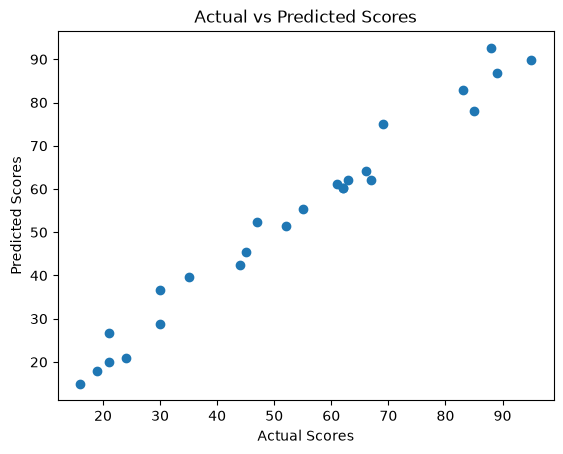

In [23]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Scores")

plt.show()

In [24]:
new_student = pd.DataFrame({"Hours": [6.5]})

prediction = model.predict(new_student)

print("Predicted Score:", prediction[0])

Predicted Score: 66.12379502997464
